# Лабораторная работа 1. Классификация растровых изображений с помощью kNN

> Напишите программу для распознавания растровых изображений, используя метод ближайшего
> соседа. Реализуйте программно равномерное и неравномерное зашумление изображений и
> сравните процент распознавания для используемых норм в случаях распознавания растровых
> бинарных изображений и изображений в градациях серого цвета для различных $k$.
> В качестве мер близости используйте предложенные выше и сравните результаты их применения.

## 1. Настройка окружения

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product

SEED = 20260919
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

## 2. Эталонные изображения

In [2]:
DIGIT_ART = {
    0: ["..####..", ".#....#.", "#......#", "#......#", "#......#", "#......#", ".#....#.", "..####.."],
    1: ["...##...", "..###...", ".####...", "#..##...", "...##...", "...##...", "...##...", "########"],
    2: [".######.", "#......#", ".......#", "......#.", "....##..", "..##....", ".#......", "########"],
    3: [".######.", "#......#", ".......#", "..#####.", ".......#", ".......#", "#......#", ".######."],
    4: ["....##..", "...#.#..", "..#..#..", ".#...#..", "#....#..", "########", ".....#..", ".....#.."],
    5: ["########", "#.......", "#.......", "#######.", ".......#", ".......#", "#......#", ".######."],
    6: [".######.", "#.......", "#.......", "#######.", "#......#", "#......#", "#......#", ".######."],
    7: ["########", ".......#", "......#.", ".....#..", "....#...", "...#....", "..#.....", "..#....."],
    8: [".######.", "#......#", "#......#", ".######.", "#......#", "#......#", "#......#", ".######."],
    9: [".######.", "#......#", "#......#", "#......#", ".#######", ".......#", "......#.", ".#####.."],
}

CLASS_NAMES = [str(c) for c in DIGIT_ART]
N_CLASSES = len(CLASS_NAMES)

# Бинарные эталоны: '#' -> 1 (чёрный), '.' -> 0 (белый)
PROTO_BIN = np.array([[[ch == "#" for ch in row] for row in DIGIT_ART[c]]
                      for c in DIGIT_ART], dtype=float)
H, W = PROTO_BIN.shape[1:]
N_FEATURES = H * W

### Эталоны в градациях серого

Полутоновой эталон — бинарный, сглаженный средним по окрестности $3 \times 3$ и растянутый на
диапазон $[0, 255]$: пиксели у края штриха получают промежуточную яркость.

In [3]:
GRAY_MAX = 255.0

# Среднее по окрестности 3x3 (с нулевым полем за границей изображения)
_pad = np.pad(PROTO_BIN, ((0, 0), (1, 1), (1, 1)))
_box = sum(_pad[:, i:i + H, j:j + W] for i in range(3) for j in range(3)) / 9

# Полутоновые эталоны: штрих + его сглаженная версия, растяжение на [0, 255]
_mix = (PROTO_BIN + _box) / 2
PROTO_GRAY = _mix / _mix.max() * GRAY_MAX

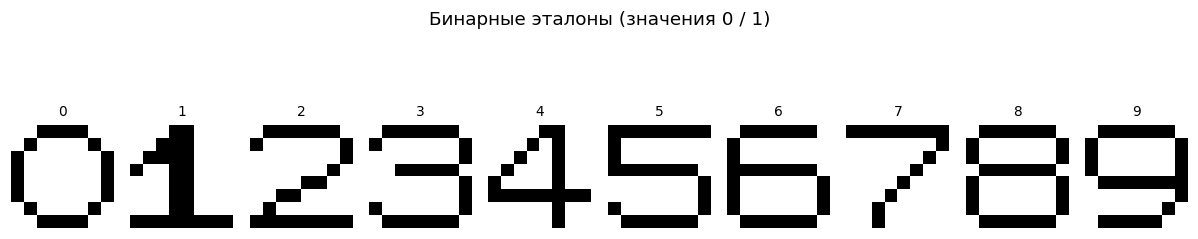

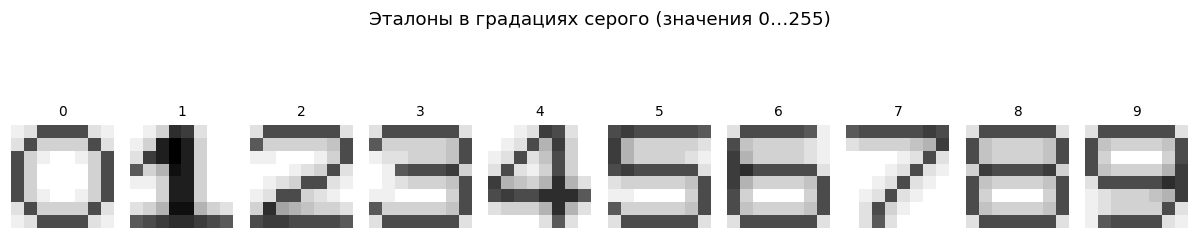

In [4]:
def show_gallery(images, titles, suptitle, vmax=1.0, ncols=10, figsize=(11, 2.6)):
    """Вывод набора изображений одной строкой (или сеткой)."""
    n = len(images)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, img, t in zip(axes, images, titles):
        ax.imshow(img, cmap="gray_r", vmin=0, vmax=vmax, interpolation="nearest")
        ax.set_title(t, fontsize=9)
    fig.suptitle(suptitle, y=1.02)
    plt.tight_layout()
    plt.show()

show_gallery(PROTO_BIN, CLASS_NAMES, "Бинарные эталоны (значения 0 / 1)", vmax=1.0)
show_gallery(PROTO_GRAY, CLASS_NAMES, "Эталоны в градациях серого (значения 0…255)", vmax=GRAY_MAX)

## 3. Модели зашумления

### 3.1. Равномерное зашумление

Для полутоновых изображений к каждому пикселю добавляется $\varepsilon_{ij} \sim \mathsf{U}[-\delta, \delta]$,
$\delta = \ell \cdot 255$, результат обрезается до $[0, 255]$ (п. 3.5). Для бинарных каждый пиксель
инвертируется с вероятностью $q = \min(\ell / 2,\ 1/2)$. Шкалы $\ell$ у двух типов несопоставимы,
поэтому их сравниваем по искажению $r$ — нормированному СКО от эталона:

$$r = \frac{1}{a_{\max}}\sqrt{\frac{1}{n^2}\sum_{i,j}\bigl(a_{ij} - a^{(p)}_{ij}\bigr)^2},
\qquad a_{\max} = \begin{cases}1, & \text{бинарные},\\ 255, & \text{градации серого}.\end{cases}$$

### 3.2. Неравномерное зашумление

Интенсивность шума умножается на карту $c_{ij}$ — горизонтальный градиент от 0,1 до 1,9 со
средним 1. Поэтому средний шум такой же, как при равномерном зашумлении, меняется только его
распределение по изображению.

In [5]:
# Карта интенсивности неравномерного шума: горизонтальный градиент со средним 1
NOISE_MAP = np.tile(np.linspace(0.1, 1.9, W), (H, 1))
assert abs(NOISE_MAP.mean() - 1.0) < 1e-12, NOISE_MAP.mean()

def noise_scale(noise_type):
    """Поэлементный коэффициент интенсивности шума."""
    if noise_type == "uniform":
        return np.ones((H, W))
    if noise_type == "nonuniform":
        return NOISE_MAP
    raise ValueError(f"неизвестный тип шума: {noise_type}")

def add_noise(images, level, image_type, noise_type, generator):
    """Зашумление набора изображений (n, H, W).

    level       — относительный уровень шума в [0, 1]
    image_type  — 'binary' | 'gray'
    noise_type  — 'uniform' | 'nonuniform'
    """
    images = np.asarray(images, dtype=float)
    scale = noise_scale(noise_type)[None, :, :]

    if image_type == "gray":
        delta = level * GRAY_MAX * scale
        eps = generator.uniform(-1.0, 1.0, size=images.shape) * delta
        return np.clip(images + eps, 0.0, GRAY_MAX)

    if image_type == "binary":
        # q ограничено 1/2: при q = 1/2 изображение уже полностью случайно
        q = np.clip(level / 2.0 * scale, 0.0, 0.5)
        flip = generator.random(size=images.shape) < q
        return np.where(flip, 1.0 - images, images)

    raise ValueError(f"неизвестный тип изображения: {image_type}")

def prototypes(image_type):
    return PROTO_BIN if image_type == "binary" else PROTO_GRAY

def vmax_of(image_type):
    return 1.0 if image_type == "binary" else GRAY_MAX

def measure_distortion(image_type, noise_type, level, n_rep=200, seed=0):
    """Нормированное СКО зашумлённого изображения от эталона (искажение r)."""
    proto = prototypes(image_type)
    base = np.repeat(proto, n_rep, axis=0)
    noisy = add_noise(base, level, image_type, noise_type, np.random.default_rng(seed))
    return float(np.sqrt(np.mean((noisy - base) ** 2)) / vmax_of(image_type))

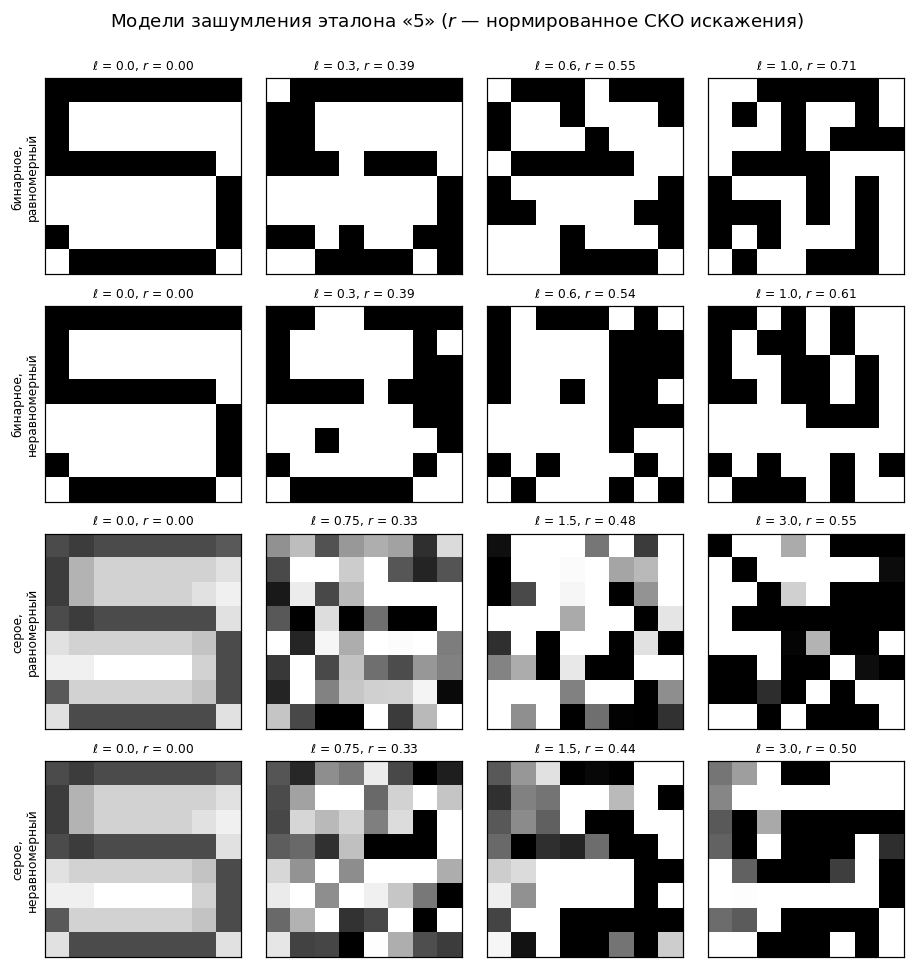

In [6]:
# Сетки уровней шума: своя для каждого типа изображений
LEVELS = {
    "binary": [0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "gray":   [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0],
}
LEVEL_TRAIN = {"binary": 0.2, "gray": 0.3}   # уровень шума обучающей выборки

# Демонстрация обеих моделей зашумления на цифре «5»
demo_rng = np.random.default_rng(SEED)
digit = 5
demo_levels = {"binary": [0.0, 0.3, 0.6, 1.0], "gray": [0.0, 0.75, 1.5, 3.0]}

fig, axes = plt.subplots(4, 4, figsize=(8.5, 8.8))
rows_cfg = [("binary", "uniform"), ("binary", "nonuniform"),
            ("gray", "uniform"), ("gray", "nonuniform")]
row_titles = ["бинарное,\nравномерный", "бинарное,\nнеравномерный",
              "серое,\nравномерный", "серое,\nнеравномерный"]

for r, ((itype, ntype), rtitle) in enumerate(zip(rows_cfg, row_titles)):
    proto = prototypes(itype)[digit][None, ...]
    for c, lvl in enumerate(demo_levels[itype]):
        noisy = add_noise(proto, lvl, itype, ntype, demo_rng)[0]
        ax = axes[r, c]
        ax.imshow(noisy, cmap="gray_r", vmin=0, vmax=vmax_of(itype), interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"$\\ell$ = {lvl}, $r$ = {measure_distortion(itype, ntype, lvl):.2f}",
                     fontsize=8)
        if c == 0:
            ax.set_ylabel(rtitle, fontsize=8)

fig.suptitle("Модели зашумления эталона «5» ($r$ — нормированное СКО искажения)", y=0.995)
plt.tight_layout()
plt.show()

При неравномерном шуме левая часть изображения почти не искажена, а правая разрушается
сильнее.

## 4. Меры близости

Пять мер близости из п. 3.2 пособия (стр. 37–38):

| Обозначение | Мера близости | Формула |
|---|---|---|
| `euclidean` | евклидово расстояние | $\rho(x,y)=\sqrt{\sum_i (x_i-y_i)^2}$ |
| `sqeuclidean` | квадрат евклидова расстояния | $\rho(x,y)=\sum_i (x_i-y_i)^2$ |
| `manhattan` | сумма модулей разностей | $\rho(x,y)=\sum_i \lvert x_i-y_i\rvert$ |
| `weighted` | взвешенное евклидово | $\rho(x,y)=\sqrt{\sum_i w_i (x_i-y_i)^2}$ |
| `chebyshev` | расстояние Чебышёва | $\rho(x,y)=\max_i \lvert x_i-y_i\rvert$ |

Вес $w_i$ — дисперсия $i$-го пикселя по эталонам, нормированная на среднюю дисперсию. Пиксель,
одинаковый у всех цифр, не помогает различать классы и получает вес около нуля.

$$w_i = \frac{\mathsf{D}_i}{\overline{\mathsf{D}}}, \qquad
\mathsf{D}_i = \frac{1}{N}\sum_{p=1}^{N}\bigl(x^{(p)}_i - \bar x_i\bigr)^2$$

In [7]:
def flatten(images):
    """(n, H, W) -> (n, H*W): конкатенация строк матрицы (стр. 42)."""
    return np.asarray(images, dtype=float).reshape(len(images), -1)

def feature_weights(image_type):
    """Веса признаков: нормированная дисперсия пикселя по множеству эталонов."""
    X = flatten(prototypes(image_type))
    var = X.var(axis=0)
    return var / var.mean()

METRICS = ["euclidean", "sqeuclidean", "manhattan", "weighted", "chebyshev"]
METRIC_LABELS = {
    "euclidean":   "евклидова",
    "sqeuclidean": "квадрат евклидовой",
    "manhattan":   "сумма модулей",
    "weighted":    "взвешенная евклидова",
    "chebyshev":   "Чебышёва",
}

def pairwise_distances(A, B, metric, weights=None, block=128):
    """Матрица попарных расстояний D[i, j] = rho(A[i], B[j]), блоками по строкам A."""
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    D = np.empty((A.shape[0], B.shape[0]), dtype=float)

    for start in range(0, A.shape[0], block):
        stop = min(start + block, A.shape[0])
        diff = A[start:stop, None, :] - B[None, :, :]   # (b, nB, m)
        if metric == "euclidean":
            D[start:stop] = np.sqrt(np.sum(diff ** 2, axis=2))
        elif metric == "sqeuclidean":
            D[start:stop] = np.sum(diff ** 2, axis=2)
        elif metric == "manhattan":
            D[start:stop] = np.sum(np.abs(diff), axis=2)
        elif metric == "weighted":
            if weights is None:
                raise ValueError("для взвешенной метрики нужны веса")
            D[start:stop] = np.sqrt(np.sum(weights[None, None, :] * diff ** 2, axis=2))
        elif metric == "chebyshev":
            D[start:stop] = np.max(np.abs(diff), axis=2)
        else:
            raise ValueError(f"неизвестная мера близости: {metric}")
    return D

## 5. Метод $k$ ближайших соседей

Алгоритм: 

1) упорядочить выборку по расстоянию до $x$
2) взять $k$ ближайших и выбрать класс, которого среди них больше
3) при взвешивании сосед голосует с весом $1/d$, где $d$ — расстояние до него.

In [8]:
def sort_neighbours(D):
    """Шаг 1: упорядочивание выборки по неубыванию расстояний.
    """
    order = np.argsort(D, axis=1, kind="stable")
    rows = np.arange(D.shape[0])[:, None]
    return order, D[rows, order]


def vote(order, dist, y_train, k, n_classes, weighted=False, eps=1e-12):
    """Шаги 2-3: k ближайших соседей и голосование (weighted — веса 1/d, п. 3.4)."""
    k = min(k, order.shape[1])
    labels = y_train[order[:, :k]]          # (n_test, k) классы k ближайших соседей
    d = dist[:, :k]                         # (n_test, k) расстояния до них

    weights = 1.0 / (d + eps) if weighted else np.ones_like(d)

    votes = np.empty((order.shape[0], n_classes), dtype=float)
    for c in range(n_classes):
        votes[:, c] = np.sum(weights * (labels == c), axis=1)
    return np.argmax(votes, axis=1)


def knn_predict(X_train, y_train, X_test, k, metric, n_classes,
                weights=None, weighted=False):
    """Полный цикл метода k ближайших соседей: шаги 1-3."""
    D = pairwise_distances(X_test, X_train, metric, weights)
    order, dist = sort_neighbours(D)
    return vote(order, dist, y_train, k, n_classes, weighted)


def accuracy(y_true, y_pred):
    """Процент распознавания."""
    return float(np.mean(y_true == y_pred))

### Формирование выборок

Обучающая выборка — 20 зашумлённых копий каждого эталона при фиксированном уровне
$\ell_{\text{train}}$. Тестовая — 50 копий на каждом исследуемом уровне шума.

In [9]:
def make_sample(n_per_class, level, image_type, noise_type, generator):
    """Выборка: n_per_class зашумлённых копий каждого эталона.

    Возвращает X (n, m) — векторы признаков, y (n,) — метки классов.
    """
    proto = prototypes(image_type)
    base = np.repeat(proto, n_per_class, axis=0)                 # (N*n_per_class, H, W)
    labels = np.repeat(np.arange(N_CLASSES), n_per_class)
    noisy = add_noise(base, level, image_type, noise_type, generator)
    return flatten(noisy), labels


N_TRAIN_PER_CLASS = 30
N_TEST_PER_CLASS  = 20

_Xtr, _ytr = make_sample(N_TRAIN_PER_CLASS, LEVEL_TRAIN["binary"], "binary", "uniform",
                         np.random.default_rng(SEED))
print("Обучающая выборка:", _Xtr.shape, "| метки:", np.bincount(_ytr))

# Фактическое искажение для обеих сеток уровней
dist_table = pd.DataFrame([
    {"тип": it, "шум": nt, "уровень l": lv,
     "искажение r": round(measure_distortion(it, nt, lv), 3)}
    for it in ["binary", "gray"] for nt in ["uniform", "nonuniform"] for lv in LEVELS[it]
]).pivot_table(index=["тип", "уровень l"], columns="шум", values="искажение r")
print("\nНормированное СКО искажения r для используемых уровней шума:")
print(dist_table.to_string())

Обучающая выборка: (300, 64) | метки: [30 30 30 30 30 30 30 30 30 30]

Нормированное СКО искажения r для используемых уровней шума:
шум               nonuniform  uniform
тип    уровень l                     
binary 0.00            0.000    0.000
       0.20            0.317    0.318
       0.40            0.447    0.448
       0.50            0.499    0.500
       0.60            0.538    0.547
       0.70            0.564    0.591
       0.80            0.583    0.632
       0.90            0.599    0.671
       1.00            0.609    0.708
gray   0.00            0.000    0.000
       0.25            0.145    0.131
       0.50            0.257    0.236
       0.75            0.335    0.331
       1.00            0.382    0.408
       1.50            0.436    0.482
       2.00            0.467    0.515
       3.00            0.502    0.546
       4.00            0.520    0.561


## 6. Вычислительный эксперимент

Перебираем все комбинации параметров:

| Параметр | Значения |
|---|---|
| тип изображения | бинарное, градации серого |
| тип зашумления | равномерное, неравномерное |
| уровень шума $\ell$ тестовой выборки | бинарные: 0 … 1,0; полутоновые: 0 … 4,0 (9 значений) |
| мера близости | все пять |
| параметр $k$ | 1, 3, 5, 7, 9, 11, 15, 21 |
| взвешивание соседей | нет, веса $1/d$ |

Матрица расстояний считается один раз на комбинацию (тип изображения, шум, уровень, мера) и
используется для всех $k$ и обеих схем взвешивания.

In [10]:
IMAGE_TYPES = ["binary", "gray"]
NOISE_TYPES = ["uniform", "nonuniform"]
K_VALUES = [1, 3, 5, 7, 9, 11, 15, 21]
WEIGHTING = [False, True]

records = []
n_dist_matrices = 0

for image_type, noise_type in product(IMAGE_TYPES, NOISE_TYPES):
    weights = feature_weights(image_type)

    # Обучающая выборка фиксирована для данной пары (тип изображения, тип шума)
    train_rng = np.random.default_rng(SEED)
    X_train, y_train = make_sample(N_TRAIN_PER_CLASS, LEVEL_TRAIN[image_type],
                                   image_type, noise_type, train_rng)

    for level in LEVELS[image_type]:
        # Своё воспроизводимое зерно для каждой конфигурации
        test_seed = (SEED
                     + 100_000 * IMAGE_TYPES.index(image_type)
                     + 10_000 * NOISE_TYPES.index(noise_type)
                     + int(round(level * 100)))
        X_test, y_test = make_sample(N_TEST_PER_CLASS, level, image_type, noise_type,
                                     np.random.default_rng(test_seed))
        # Фактическое искажение измеряется один раз на конфигурацию
        distortion = measure_distortion(image_type, noise_type, level)

        for metric in METRICS:
            D = pairwise_distances(X_test, X_train, metric, weights)
            n_dist_matrices += 1
            # Сортировка одна на все k и схемы взвешивания
            order, dist = sort_neighbours(D)

            for k, weighted in product(K_VALUES, WEIGHTING):
                y_pred = vote(order, dist, y_train, k, N_CLASSES, weighted)
                records.append({
                    "image_type": image_type,
                    "noise_type": noise_type,
                    "level": level,
                    "distortion": distortion,
                    "metric": metric,
                    "k": k,
                    "weighted": weighted,
                    "accuracy": accuracy(y_test, y_pred),
                })

results = pd.DataFrame.from_records(records)
print(f"Вычислено матриц расстояний: {n_dist_matrices}")
print(f"Получено замеров точности:   {len(results)}")
results.head()

Вычислено матриц расстояний: 180
Получено замеров точности:   2880


,image_type,noise_type,level,distortion,metric,k,weighted,accuracy
0,binary,uniform,0.0,0.0,euclidean,1,False,1.0
1,binary,uniform,0.0,0.0,euclidean,1,True,1.0
2,binary,uniform,0.0,0.0,euclidean,3,False,1.0
3,binary,uniform,0.0,0.0,euclidean,3,True,1.0
4,binary,uniform,0.0,0.0,euclidean,5,False,1.0


## 7. Анализ результатов

### 7.1. Проверка замечаний о мерах близости

In [11]:
# (1) Евклидова мера и её квадрат при невзвешенном голосовании должны совпасть в точности
pair = (results[~results.weighted]
        .pivot_table(index=["image_type", "noise_type", "level", "k"],
                     columns="metric", values="accuracy"))
max_gap = (pair["euclidean"] - pair["sqeuclidean"]).abs().max()
print(f"Максимальное расхождение euclidean vs sqeuclidean (без весов): {max_gap:.12f}")
assert max_gap < 1e-12, "порядок соседей должен совпадать"

# (2) На бинарных изображениях манхэттенская мера тоже должна совпасть с квадратом евклидовой
binary_pair = pair.loc["binary"]
gap_bin = (binary_pair["manhattan"] - binary_pair["sqeuclidean"]).abs().max()
print(f"Максимальное расхождение manhattan vs sqeuclidean (бинарные):  {gap_bin:.12f}")

# (3) Расстояние Чебышёва на бинарных векторах принимает лишь значения 0 и 1
_Xb, _yb = make_sample(5, 0.3, "binary", "uniform", np.random.default_rng(1))
_Db = pairwise_distances(_Xb, _Xb, "chebyshev")
print("Различные значения меры Чебышёва на бинарных данных:", np.unique(_Db))

Максимальное расхождение euclidean vs sqeuclidean (без весов): 0.000000000000
Максимальное расхождение manhattan vs sqeuclidean (бинарные):  0.000000000000
Различные значения меры Чебышёва на бинарных данных: [0. 1.]


Замечания подтверждаются. На бинарных изображениях по сути различаются только две меры:
евклидова (с эквивалентными ей) и взвешенная евклидова.

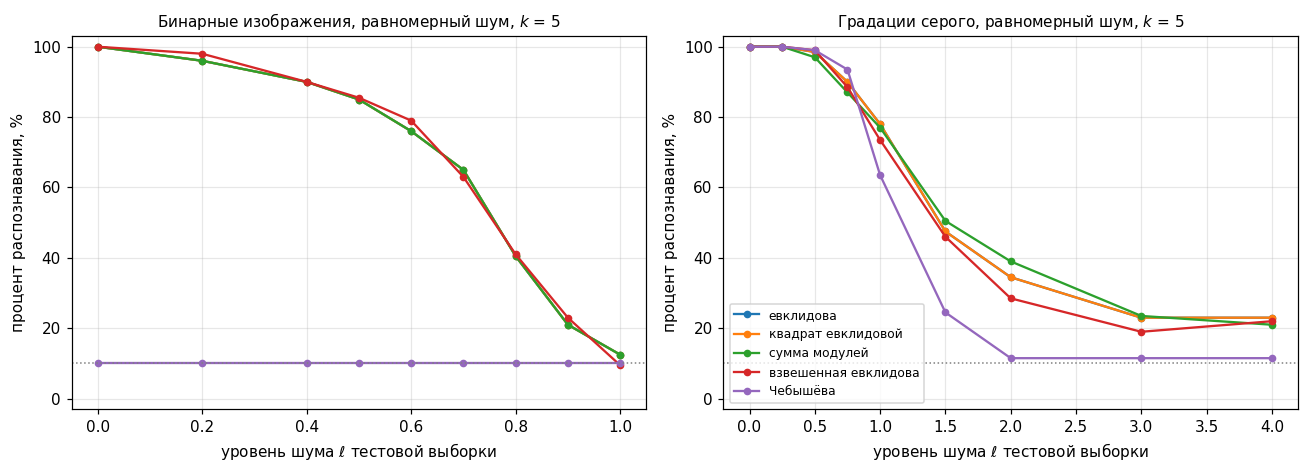

In [12]:
def accuracy_curves(df, image_type, noise_type, weighted, k, ax, title):
    sub = df[(df.image_type == image_type) & (df.noise_type == noise_type)
             & (df.weighted == weighted) & (df.k == k)]
    for metric in METRICS:
        s = sub[sub.metric == metric].sort_values("level")
        ax.plot(s.level, s.accuracy * 100, marker="o", ms=4, label=METRIC_LABELS[metric])
    ax.axhline(10, color="gray", ls=":", lw=1)      # уровень случайного угадывания
    ax.set_xlabel("уровень шума $\\ell$ тестовой выборки")
    ax.set_ylabel("процент распознавания, %")
    ax.set_ylim(-3, 103)
    ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
accuracy_curves(results, "binary", "uniform", False, 5, axes[0],
                "Бинарные изображения, равномерный шум, $k$ = 5")
accuracy_curves(results, "gray", "uniform", False, 5, axes[1],
                "Градации серого, равномерный шум, $k$ = 5")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

### 7.2. Сравнение мер близости

Средняя точность по всем уровням шума и значениям $k$.

In [13]:
metric_summary = (results
                  .pivot_table(index="metric", columns=["image_type", "noise_type"],
                               values="accuracy", aggfunc="mean")
                  .reindex(METRICS) * 100).round(2)
metric_summary.index = [METRIC_LABELS[m] for m in metric_summary.index]
print("Средний процент распознавания по всем уровням шума, k и схемам взвешивания:\n")
metric_summary

Средний процент распознавания по всем уровням шума, k и схемам взвешивания:



image_type               binary               gray        
noise_type           nonuniform uniform nonuniform uniform
евклидова                 87.27   64.89      80.73   65.53
квадрат евклидовой        87.27   64.90      80.73   65.53
сумма модулей             87.27   64.90      84.12   65.83
взвешенная евклидова      89.03   65.02      82.15   64.24
Чебышёва                  10.63   10.00      44.80   56.35

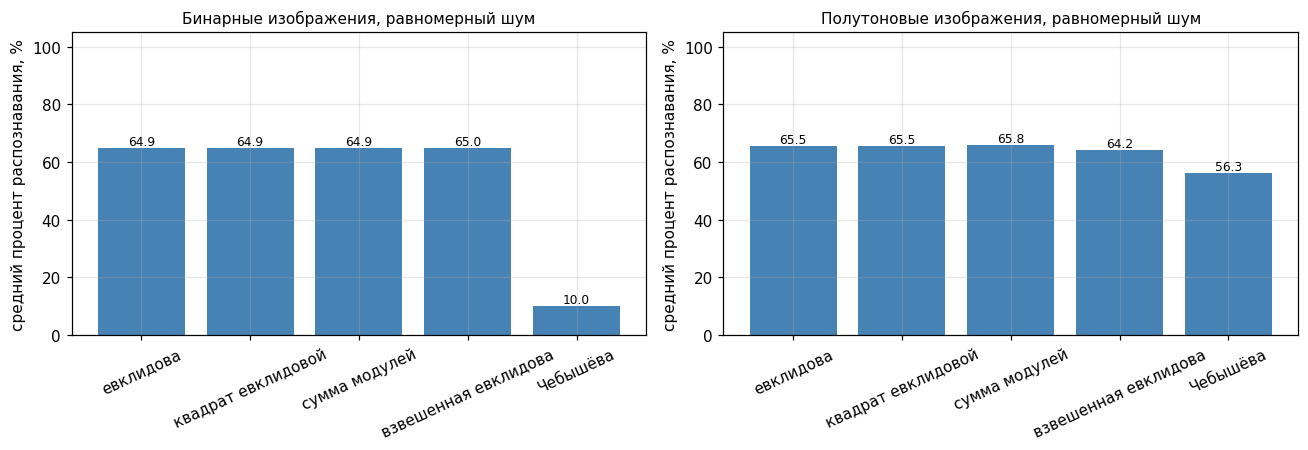

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, image_type in zip(axes, IMAGE_TYPES):
    sub = results[(results.image_type == image_type) & (results.noise_type == "uniform")]
    means = sub.groupby("metric").accuracy.mean().reindex(METRICS) * 100
    bars = ax.bar([METRIC_LABELS[m] for m in METRICS], means.values, color="steelblue")
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
    ax.set_ylabel("средний процент распознавания, %")
    ax.set_ylim(0, 105)
    ax.set_title(f"{'Бинарные' if image_type == 'binary' else 'Полутоновые'} изображения, "
                 f"равномерный шум", fontsize=10)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

### 7.3. Влияние параметра $k$

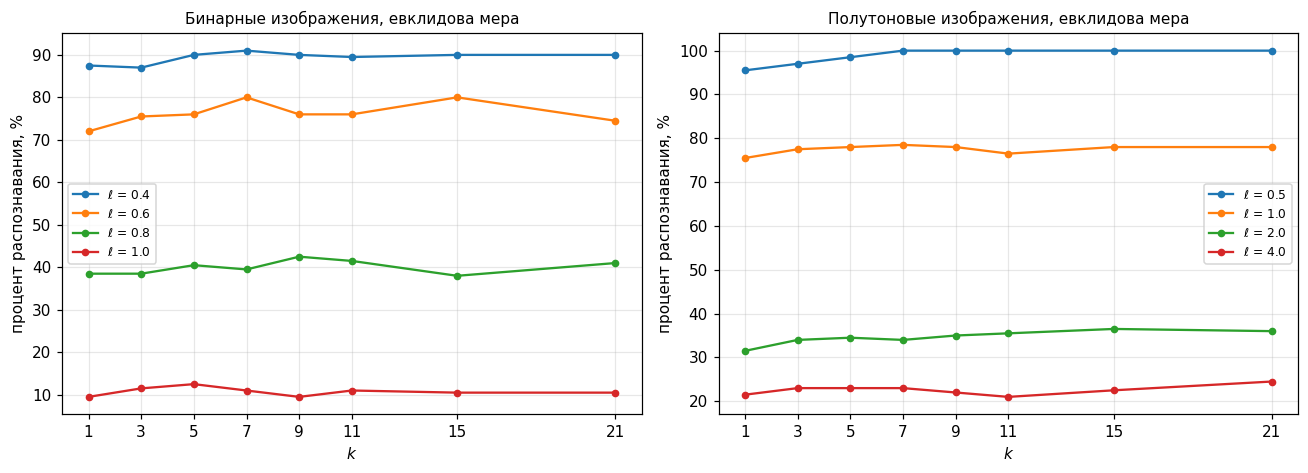


Наилучшее k для каждого уровня шума (усреднение по мерам и схемам взвешивания):
image_type  level  k  accuracy
    binary   0.00 21     82.00
    binary   0.20 21     80.00
    binary   0.40  7     74.60
    binary   0.50 21     72.40
    binary   0.60 15     65.65
    binary   0.70  3     53.95
    binary   0.80  9     35.35
    binary   0.90  5     19.65
    binary   1.00 11     11.05
      gray   0.00  1    100.00
      gray   0.25  3    100.00
      gray   0.50 21     99.55
      gray   0.75 15     90.45
      gray   1.00 11     75.00
      gray   1.50  5     42.70
      gray   2.00 15     30.50
      gray   3.00 21     20.25
      gray   4.00 21     20.50


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, image_type in zip(axes, IMAGE_TYPES):
    sub = results[(results.image_type == image_type) & (results.noise_type == "uniform")
                  & (~results.weighted) & (results.metric == "euclidean")]
    for level in LEVELS[image_type][2::2]:      # средние и высокие уровни шума
        s = sub[sub.level == level].sort_values("k")
        ax.plot(s.k, s.accuracy * 100, marker="o", ms=4, label=f"$\\ell$ = {level}")
    ax.set_xlabel("$k$")
    ax.set_ylabel("процент распознавания, %")
    ax.set_xticks(K_VALUES)
    ax.set_title(f"{'Бинарные' if image_type == 'binary' else 'Полутоновые'} изображения, "
                 f"евклидова мера", fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

best_k = (results[results.noise_type == "uniform"]
          .groupby(["image_type", "level", "k"]).accuracy.mean()
          .reset_index()
          .sort_values("accuracy", ascending=False)
          .groupby(["image_type", "level"]).head(1)
          .sort_values(["image_type", "level"]))
print("\nНаилучшее k для каждого уровня шума (усреднение по мерам и схемам взвешивания):")
print(best_k.assign(accuracy=lambda d: (d.accuracy * 100).round(2)).to_string(index=False))

### 7.4. Бинарные изображения против градаций серого

Шкалы $\ell$ разные, поэтому сравниваем по искажению $r$.

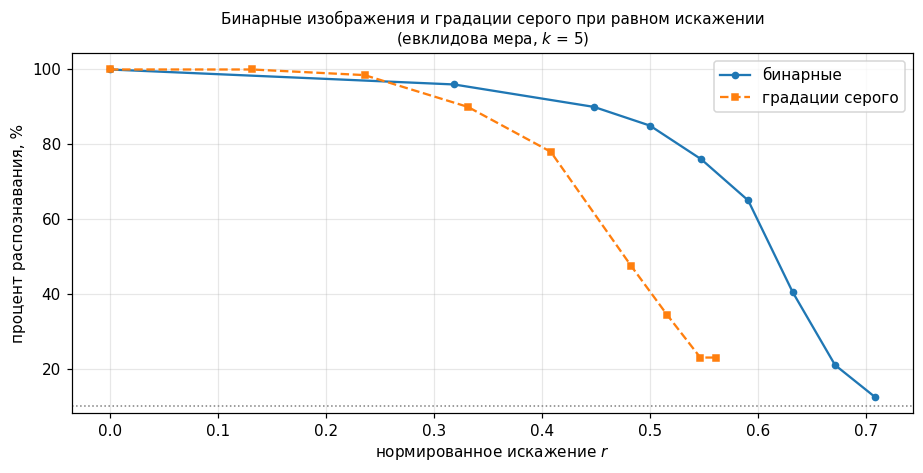


Средняя точность и искажение по уровням шума:
                  искажение  точность
image_type level                     
binary     0.00       0.000     82.00
           0.20       0.318     79.57
           0.40       0.448     73.76
           0.50       0.500     70.31
           0.60       0.547     63.45
           0.70       0.591     53.16
           0.80       0.632     34.01
           0.90       0.671     18.83
           1.00       0.708     10.39
gray       0.00       0.000    100.00
           0.25       0.131     99.99
           0.50       0.236     98.56
           0.75       0.331     89.11
           1.00       0.408     73.83
           1.50       0.482     41.14
           2.00       0.515     29.39
           3.00       0.546     19.77
           4.00       0.561     19.68


In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for image_type, style in zip(IMAGE_TYPES, ["-o", "--s"]):
    sub = results[(results.image_type == image_type) & (results.noise_type == "uniform")
                  & (~results.weighted) & (results.metric == "euclidean") & (results.k == 5)]
    s = sub.sort_values("distortion")
    ax.plot(s.distortion, s.accuracy * 100, style, ms=4,
            label="бинарные" if image_type == "binary" else "градации серого")
ax.axhline(10, color="gray", ls=":", lw=1)
ax.set_xlabel("нормированное искажение $r$")
ax.set_ylabel("процент распознавания, %")
ax.set_title("Бинарные изображения и градации серого при равном искажении\n"
             "(евклидова мера, $k$ = 5)", fontsize=10)
ax.legend()
plt.tight_layout()
plt.show()

cmp_types = (results[results.noise_type == "uniform"]
             .groupby(["image_type", "level"])
             .agg(искажение=("distortion", "first"),
                  точность=("accuracy", "mean")))
cmp_types["искажение"] = cmp_types["искажение"].round(3)
cmp_types["точность"] = (cmp_types["точность"] * 100).round(2)
print("\nСредняя точность и искажение по уровням шума:")
print(cmp_types.to_string())

### 7.5. Равномерное зашумление против неравномерного

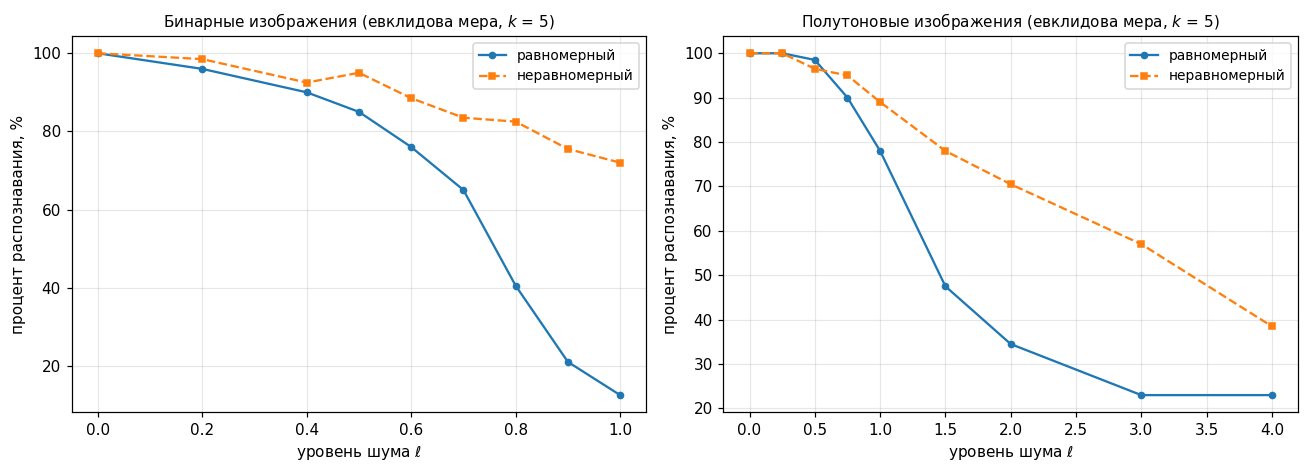


Средний процент распознавания:
noise_type        nonuniform  uniform  разница
image_type level                              
binary     0.00        83.12    82.00     1.12
           0.20        80.67    79.57     1.10
           0.40        77.62    73.76     3.86
           0.50        77.02    70.31     6.71
           0.60        71.92    63.45     8.47
           0.70        69.13    53.16    15.97
           0.80        67.12    34.01    33.11
           0.90        63.78    18.83    44.95
           1.00        60.26    10.39    49.87
gray       0.00       100.00   100.00     0.00
           0.25        99.68    99.99    -0.31
           0.50        92.59    98.56    -5.97
           0.75        86.24    89.11    -2.87
           1.00        79.08    73.83     5.25
           1.50        67.73    41.14    26.59
           2.00        60.14    29.39    30.75
           3.00        49.39    19.77    29.62
           4.00        35.68    19.68    16.00


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, image_type in zip(axes, IMAGE_TYPES):
    for noise_type, style in zip(NOISE_TYPES, ["-o", "--s"]):
        sub = results[(results.image_type == image_type) & (results.noise_type == noise_type)
                      & (~results.weighted) & (results.metric == "euclidean") & (results.k == 5)]
        s = sub.sort_values("level")
        ax.plot(s.level, s.accuracy * 100, style, ms=4,
                label="равномерный" if noise_type == "uniform" else "неравномерный")
    ax.set_xlabel("уровень шума $\\ell$")
    ax.set_ylabel("процент распознавания, %")
    ax.set_title(f"{'Бинарные' if image_type == 'binary' else 'Полутоновые'} изображения "
                 f"(евклидова мера, $k$ = 5)", fontsize=10)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

cmp_noise = (results.pivot_table(index=["image_type", "level"], columns="noise_type",
                                 values="accuracy") * 100).round(2)
cmp_noise["разница"] = (cmp_noise["nonuniform"] - cmp_noise["uniform"]).round(2)
print("\nСредний процент распознавания:")
print(cmp_noise.to_string())

### 7.6. Влияние взвешивания соседей

Средний процент распознавания, влияние взвешивания соседей:

                        без весов  веса 1/d  прирост
image_type metric                                   
binary     chebyshev        10.07     10.56     0.49
           euclidean        75.96     76.20     0.24
           manhattan        75.96     76.21     0.25
           sqeuclidean      75.96     76.21     0.25
           weighted         77.00     77.06     0.06
gray       chebyshev        50.39     50.76     0.37
           euclidean        73.15     73.11    -0.04
           manhattan        74.94     75.01     0.07
           sqeuclidean      73.15     73.11    -0.04
           weighted         73.22     73.17    -0.05


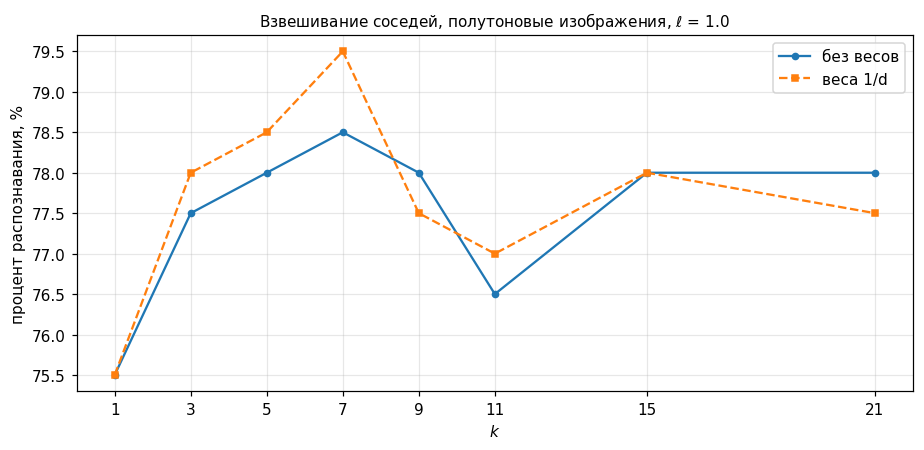

In [18]:
weight_effect = (results.pivot_table(index=["image_type", "metric"], columns="weighted",
                                     values="accuracy") * 100).round(2)
weight_effect.columns = ["без весов", "веса 1/d"]
weight_effect["прирост"] = (weight_effect["веса 1/d"] - weight_effect["без весов"]).round(2)
print("Средний процент распознавания, влияние взвешивания соседей:\n")
print(weight_effect.to_string())

fig, ax = plt.subplots(figsize=(8.5, 4.2))
HARD_GRAY = 1.0      # уровень, при котором полутоновые изображения уже плохо различимы
sub = results[(results.image_type == "gray") & (results.noise_type == "uniform")
              & (results.metric == "euclidean") & (results.level == HARD_GRAY)]
for weighted, style in zip(WEIGHTING, ["-o", "--s"]):
    s = sub[sub.weighted == weighted].sort_values("k")
    ax.plot(s.k, s.accuracy * 100, style, ms=4,
            label="веса 1/d" if weighted else "без весов")
ax.set_xlabel("$k$"); ax.set_ylabel("процент распознавания, %")
ax.set_xticks(K_VALUES)
ax.set_title(f"Взвешивание соседей, полутоновые изображения, $\\ell$ = {HARD_GRAY}",
             fontsize=10)
ax.legend()
plt.tight_layout()
plt.show()

### 7.7. Сводная таблица и наилучшая конфигурация

In [19]:
for image_type in IMAGE_TYPES:
    pivot = (results[(~results.weighted) & (results.image_type == image_type)]
             .pivot_table(index="metric", columns="level",
                          values="accuracy", aggfunc="mean")
             .reindex(METRICS) * 100).round(1)
    pivot.index = [METRIC_LABELS[m] for m in pivot.index]
    print(f"{'Бинарные' if image_type == 'binary' else 'Полутоновые'} изображения: "
          f"процент распознавания по уровням шума")
    print("(усреднение по типам шума и k, без взвешивания соседей)\n")
    print(pivot.to_string())
    print()

# Лучшие конфигурации при сильном шуме: последний уровень сетки для каждого типа
print("\nЛучшие конфигурации при сильном шуме:")
for image_type in IMAGE_TYPES:
    hard = LEVELS[image_type][-2]
    best = (results[(results.image_type == image_type) & (results.level == hard)]
            .sort_values("accuracy", ascending=False)
            .head(5)
            .assign(accuracy=lambda d: (d.accuracy * 100).round(2)))
    print(f"\n{image_type}, l = {hard}:")
    print(best[["noise_type", "metric", "k", "weighted", "accuracy"]].to_string(index=False))

Бинарные изображения: процент распознавания по уровням шума
(усреднение по типам шума и k, без взвешивания соседей)

level                   0.0   0.2   0.4   0.5   0.6   0.7   0.8   0.9   1.0
евклидова             100.0  97.1  91.7  89.2  81.4  74.1  60.1  48.9  41.1
квадрат евклидовой    100.0  97.1  91.7  89.2  81.4  74.1  60.1  48.9  41.1
сумма модулей         100.0  97.1  91.7  89.2  81.4  74.1  60.1  48.9  41.1
взвешенная евклидова  100.0  98.8  93.2  89.5  83.6  73.5  61.7  49.3  43.3
Чебышёва               10.6  10.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0

Полутоновые изображения: процент распознавания по уровням шума
(усреднение по типам шума и k, без взвешивания соседей)

level                  0.00   0.25  0.50  0.75  1.00  1.50  2.00  3.00  4.00
евклидова             100.0   99.9  97.9  92.3  83.2  62.2  52.1  39.3  31.4
квадрат евклидовой    100.0   99.9  97.9  92.3  83.2  62.2  52.1  39.3  31.4
сумма модулей         100.0   99.8  98.1  91.8  85.0  66.3  56.7  44.1  32.

### 7.8. Матрица ошибок

Какие цифры путаются при сильном шуме.

Точность: 79.50 %



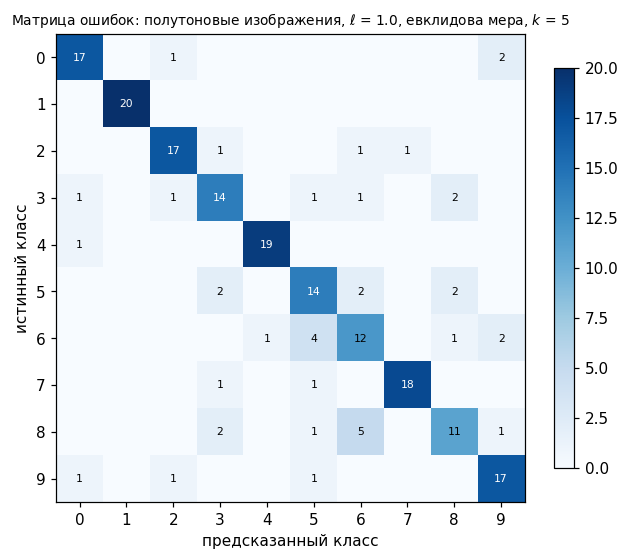

Наиболее частые ошибки (истинный -> предсказанный):
  8 -> 6: 5
  6 -> 5: 4
  0 -> 9: 2
  3 -> 8: 2
  5 -> 3: 2
  5 -> 6: 2
  5 -> 8: 2
  6 -> 9: 2


In [20]:
def confusion_matrix(y_true, y_pred, n_classes):
    M = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        M[t, p] += 1
    return M

CM_LEVEL = 1.0
cm_rng = np.random.default_rng(SEED + 1)
X_train, y_train = make_sample(N_TRAIN_PER_CLASS, LEVEL_TRAIN["gray"], "gray", "uniform",
                               np.random.default_rng(SEED))
X_test, y_test = make_sample(N_TEST_PER_CLASS, CM_LEVEL, "gray", "uniform", cm_rng)
y_pred = knn_predict(X_train, y_train, X_test, k=5, metric="euclidean", n_classes=N_CLASSES)

cm = confusion_matrix(y_test, y_pred, N_CLASSES)
print(f"Точность: {accuracy(y_test, y_pred) * 100:.2f} %\n")

fig, ax = plt.subplots(figsize=(6, 5.2))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(N_CLASSES), CLASS_NAMES)
ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
ax.set_xlabel("предсказанный класс"); ax.set_ylabel("истинный класс")
ax.set_title(f"Матрица ошибок: полутоновые изображения, $\\ell$ = {CM_LEVEL}, "
             f"евклидова мера, $k$ = 5", fontsize=9)
ax.grid(False)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

errors = [(CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j])
          for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j and cm[i, j] > 0]
errors.sort(key=lambda t: -t[2])
print("Наиболее частые ошибки (истинный -> предсказанный):")
for t, p, c in errors[:8]:
    print(f"  {t} -> {p}: {c}")

## 8. Выводы

* **Меры близости.** Евклидова мера, её квадрат и (на бинарных) сумма модулей дают одинаковый
  результат. Чебышёв на бинарных — 10 % (случайное угадывание), на полутоновых при $\ell = 1$ —
  59,1 % против 72,9 % у евклидовой.
* **Взвешенная евклидова мера** помогает только на бинарных: 64,5 % против 63,6 % в среднем,
  85,1 % против 82,5 % при $\ell = 0{,}5$.
* **Параметр $k$.** При сильном шуме бо́льшие $k$ лучше: бинарные, $\ell = 0{,}6$ — 71 % при $k = 1$
  и 76 % при $k = 15$; полутоновые, $\ell = 1$ — 69 % и 72–75 %. Без шума $k = 1$ даёт на бинарных
  лишь 90 %: обучающая выборка зашумлена, а эталоны 6/8 и 5/6 отличаются 3–4 пикселями.
* **Бинарные против полутоновых.** При равном искажении бинарные распознаются лучше: 88 % при
  $r = 0{,}45$ против 72 % у полутоновых уже при $r = 0{,}41$.
* **Неравномерный шум** при сильном зашумлении даёт более высокую точность, так как левая часть
  изображения почти не искажена: у бинарных +43,9…51,7 п. п. при $\ell = 0{,}9\ldots1$, у полутоновых
  +27…31 п. п. при $\ell = 1{,}5\ldots2$. При $\ell = 0{,}5\ldots0{,}75$ у полутоновых он хуже на
  2,6…5,1 п. п.
* **Взвешивание соседей $1/d$** даёт прирост 0–0,5 п. п., при $k = 1$ не влияет.
* **Ошибки.** Полутоновые при $\ell = 1$ распознаются на 72,4 %, чаще всего путаются 3 → 8, 8 → 6,
  6 → 8, 5 → 6.